# Mini-StyleGAN sur MNIST — Q1 à Q20
Amjad AAYD — [information masquée]

Code pédagogique commenté.

## Stabilisation après un premier essai effondré
Le premier essai a produit des images presque identiques malgré des codes différents. Il est conservé dans `premier_essai_effondrement/`. Cette seconde exécution ajoute au discriminateur une carte contenant l’écart-type moyen du batch, suivie d’une convolution. Le discriminateur peut ainsi observer la diversité d’un lot. Les autres mécanismes du Mini-StyleGAN et le budget de 15 époques restent identiques. La comparaison de deux essais ne constitue pas une ablation statistique contrôlée.

## Q1–Q2 : principes et usages responsables
Un GAN classique injecte z à l’entrée. Le Mini-StyleGAN transforme z en w, puis applique ce style à plusieurs résolutions. Z suit la loi choisie ; W est appris par le mapping. Usages : création artistique et simulation pédagogique. Risques : tromperie et biais. Bonnes pratiques : identifier les images synthétiques et utiliser des données autorisées sans usurper une identité.

In [1]:
# Importer les outils et fixer les graines pour documenter l'expérience.
from pathlib import Path
import json, random, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
from sklearn import datasets as skdata
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score
from sklearn.manifold import TSNE
from threadpoolctl import threadpool_limits
random.seed(42); np.random.seed(42); torch.manual_seed(42)
torch.set_num_threads(4)
# Préférer MPS, puis CUDA, puis le CPU conformément au sujet StyleGAN.
def choisir_device():
    if torch.backends.mps.is_available(): return torch.device('mps')
    if torch.cuda.is_available(): return torch.device('cuda')
    return torch.device('cpu')
device=choisir_device(); print('Périphérique :',device)
Path('figures').mkdir(exist_ok=True);Path('models').mkdir(exist_ok=True)
def figure(nom):
    plt.tight_layout();plt.savefig('figures/'+nom+'.png',dpi=140);plt.show();plt.close()
def grille(images,nom,ncol=10):
    images=images.detach().cpu(); nrow=(len(images)+ncol-1)//ncol
    fig,axes=plt.subplots(nrow,ncol,figsize=(ncol,nrow),squeeze=False)
    for ax in axes.flat:ax.axis('off')
    for ax,img in zip(axes.flat,images):ax.imshow(img.squeeze(),cmap='gray',vmin=-1,vmax=1)
    figure(nom)


Périphérique : cuda


## Q3–Q4 : périphérique et données

Batch : torch.Size([256, 1, 28, 28]) pixels : -1.0 1.0


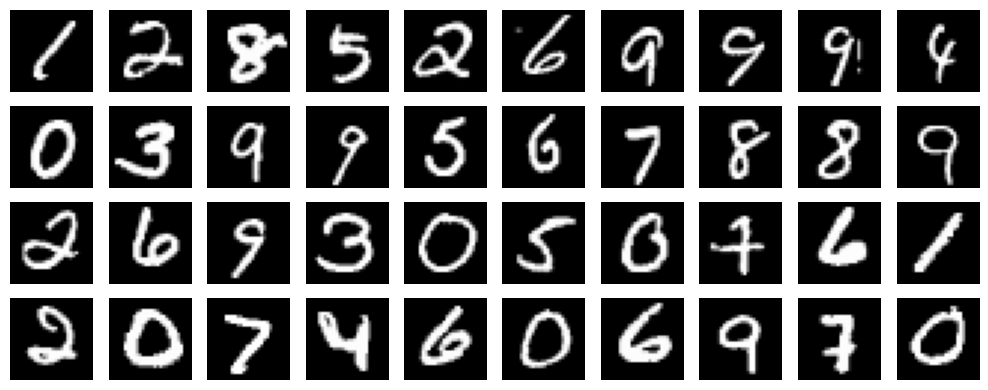

In [2]:
# Charger les vrais jeux MNIST, avec un DataLoader sans workers supplémentaires.
train=datasets.MNIST('../data',train=True,download=True,transform=transforms.Compose([transforms.ToTensor(),transforms.Normalize((.5,),(.5,))]))
test=datasets.MNIST('../data',train=False,download=True,transform=train.transform)
# Préparer une seule fois les pixels normalisés, pour éviter le coût des transformations image par image à chaque époque.
train_tensor=TensorDataset(train.data[:,None].float()/127.5-1,train.targets)
loader=DataLoader(train_tensor,batch_size=256,shuffle=True,num_workers=0)
images,labels=next(iter(loader));print('Batch :',images.shape,'pixels :',float(images.min()),float(images.max()))
grille(images[:40],'images_reelles')


## Q5–Q10 : mapping, AdaIN, bruit et synthèse
La normalisation de z réduit les variations d’échelle. AdaIN normalise chaque carte puis applique gamma(w) et beta(w). Le bruit spatial, pondéré par un coefficient appris, peut modifier de petits détails. La constante apprise démarre en 7×7 et deux agrandissements donnent 28×28.

In [3]:
# Transformer les styles en échelles et biais pour chaque canal.
class AdaIN(nn.Module):
    def __init__(self,c,w=64):
        super().__init__();self.affine=nn.Linear(w,2*c)
    def forward(self,x,w):
        mu=x.mean((2,3),keepdim=True);std=x.var((2,3),unbiased=False,keepdim=True).add(1e-8).sqrt()
        gamma,beta=self.affine(w).chunk(2,1)
        return (x-mu)/std*(1+gamma[:,:,None,None])+beta[:,:,None,None]
class Bruit(nn.Module):
    def __init__(self,c):super().__init__();self.alpha=nn.Parameter(torch.zeros(1,c,1,1))
    def forward(self,x,noise=None):
        if noise is None:noise=torch.randn(x.shape[0],1,x.shape[2],x.shape[3],device=x.device)
        return x+self.alpha*noise
class Bloc(nn.Module):
    def __init__(self,ci,co,up=False):
        super().__init__();self.up=up;self.conv=nn.Conv2d(ci,co,3,padding=1);self.noise=Bruit(co);self.norm=AdaIN(co)
    def forward(self,x,w,noise=None):
        if self.up:x=F.interpolate(x,scale_factor=2,mode='nearest')
        return self.norm(F.leaky_relu(self.noise(self.conv(x),noise),.2),w)
class MiniStyleGAN(nn.Module):
    def __init__(self):
        super().__init__();self.mapping=nn.Sequential(nn.Linear(64,64),nn.LeakyReLU(.2),nn.Linear(64,64),nn.LeakyReLU(.2),nn.Linear(64,64))
        self.const=nn.Parameter(torch.randn(1,64,7,7));self.blocks=nn.ModuleList([Bloc(64,64),Bloc(64,32,True),Bloc(32,16,True)]);self.toimage=nn.Conv2d(16,1,1)
    def mapper(self,z):return self.mapping(z/(z.square().mean(1,keepdim=True)+1e-8).sqrt())
    def synthese(self,w,w2=None,cut=1,noises=None):
        x=self.const.expand(len(w),-1,-1,-1)
        for k,block in enumerate(self.blocks):x=block(x,w2 if w2 is not None and k>=cut else w,None if noises is None else noises[k])
        return torch.tanh(self.toimage(x))
    def forward(self,z,z2=None,noises=None):return self.synthese(self.mapper(z),None if z2 is None else self.mapper(z2),noises=noises)
G=MiniStyleGAN().to(device)
# Ajouter une statistique de diversité au discriminateur pour détecter les lots effondrés.
class EcartTypeBatch(nn.Module):
    def forward(self,x):
        ecart=(x.var(dim=0,unbiased=False)+1e-8).sqrt().mean()
        carte=ecart.expand(len(x),1,x.shape[2],x.shape[3])
        return torch.cat([x,carte],dim=1)
D=nn.Sequential(nn.Conv2d(1,32,4,2,1),nn.LeakyReLU(.2),nn.Conv2d(32,64,4,2,1),nn.LeakyReLU(.2),EcartTypeBatch(),nn.Conv2d(65,64,3,padding=1),nn.LeakyReLU(.2),nn.Flatten(),nn.Linear(64*7*7,1),nn.Sigmoid()).to(device)
print('Sortie G :',G(torch.randn(2,64,device=device)).shape)


Sortie G : torch.Size([2, 1, 28, 28])


## Q11–Q12 : entraînement et générations après chaque époque
Deux optimiseurs alternent. Les fausses images sont détachées pendant la mise à jour du discriminateur. Les codes et le bruit de visualisation sont fixes pour rendre les grilles comparables.

Époque 1 D / G [1.2223407139169409, 0.861907775097705]


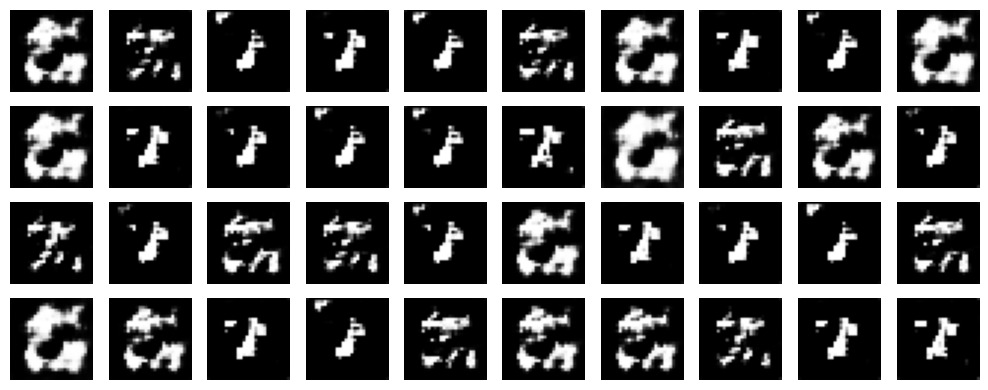

Époque 2 D / G [1.3062581772499897, 0.799388668131321]


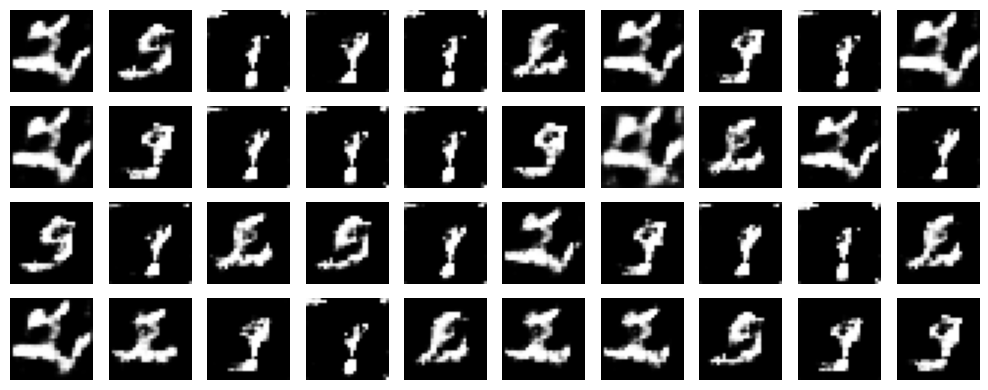

Époque 3 D / G [1.2770491092763048, 0.8259030217820026]


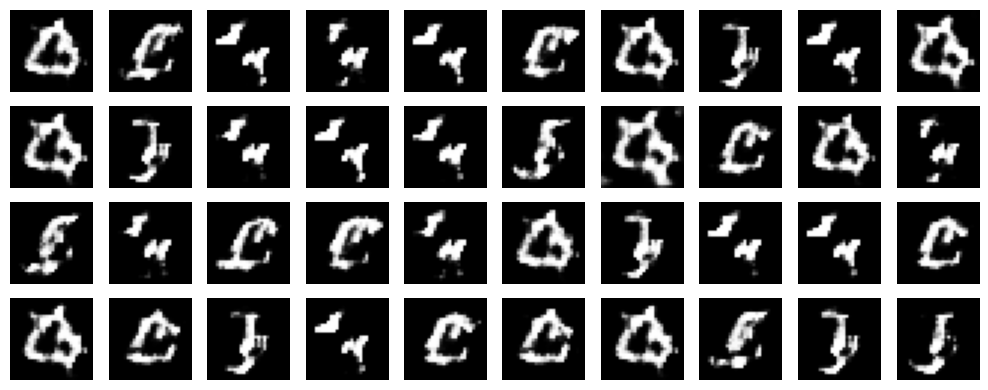

Époque 4 D / G [1.2448111721809874, 0.846546300167733]


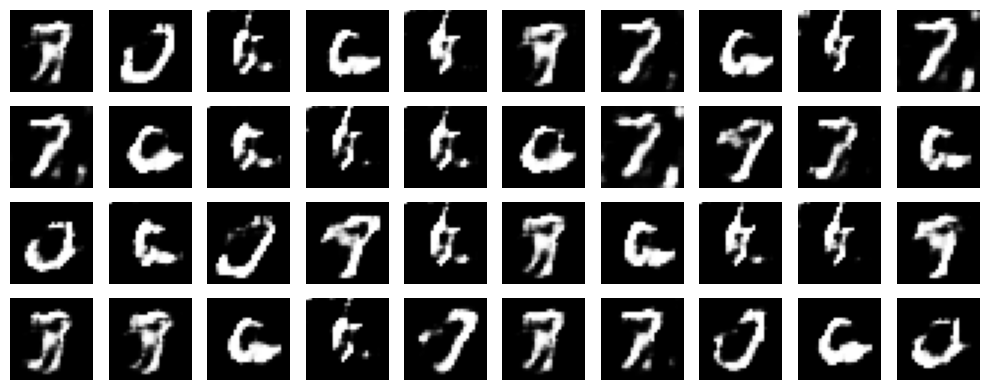

Époque 5 D / G [1.2720930510378898, 0.8298019462443412]


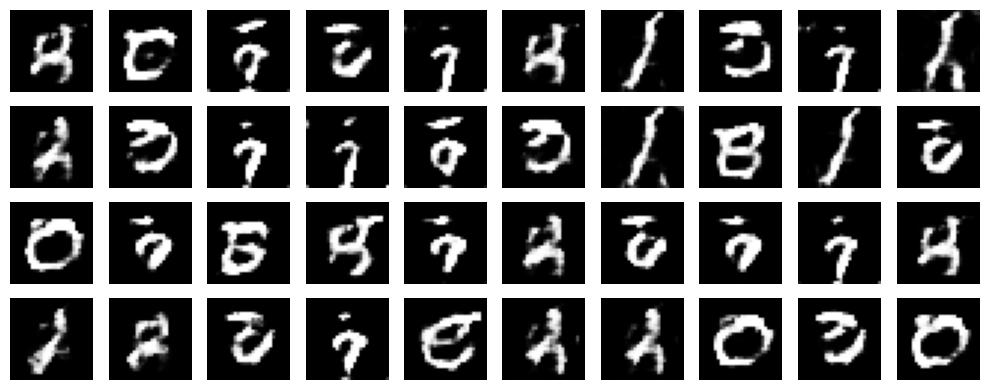

Époque 6 D / G [1.2781372303658343, 0.8090979144928303]


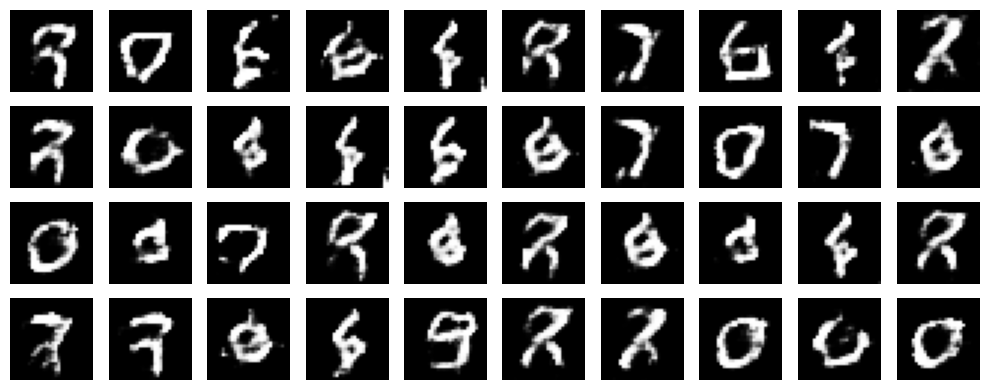

Époque 7 D / G [1.2799882650375367, 0.8066434708047421]


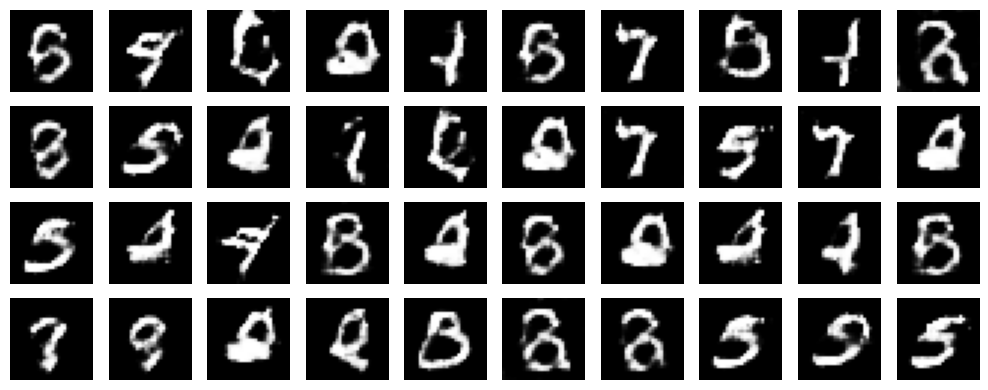

Époque 8 D / G [1.2796235515716228, 0.8168861460178456]


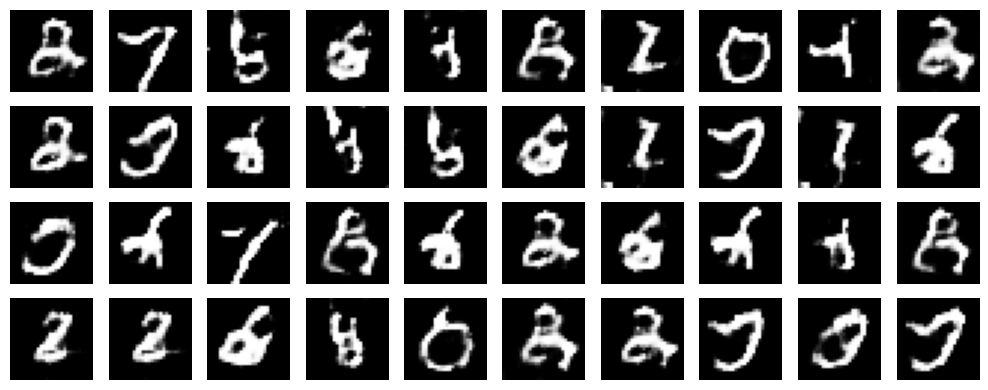

Époque 9 D / G [1.2581453774837736, 0.8379084153378263]


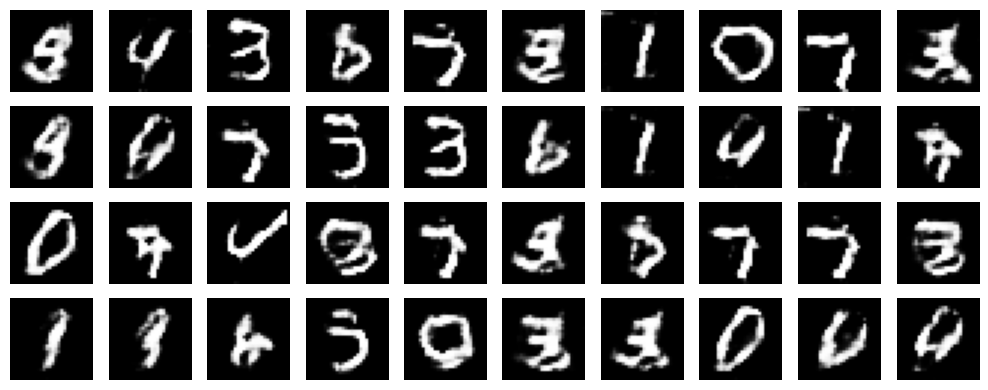

Époque 10 D / G [1.2209687517044392, 0.8761649280152423]


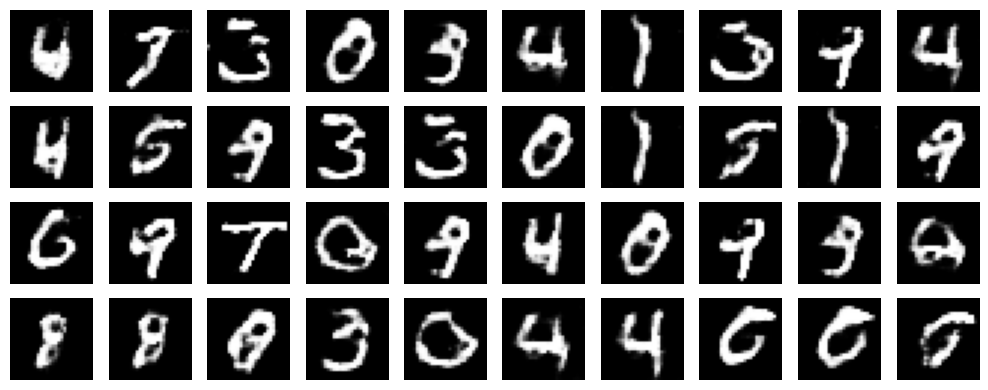

Époque 11 D / G [1.235842219819414, 0.8702552740878248]


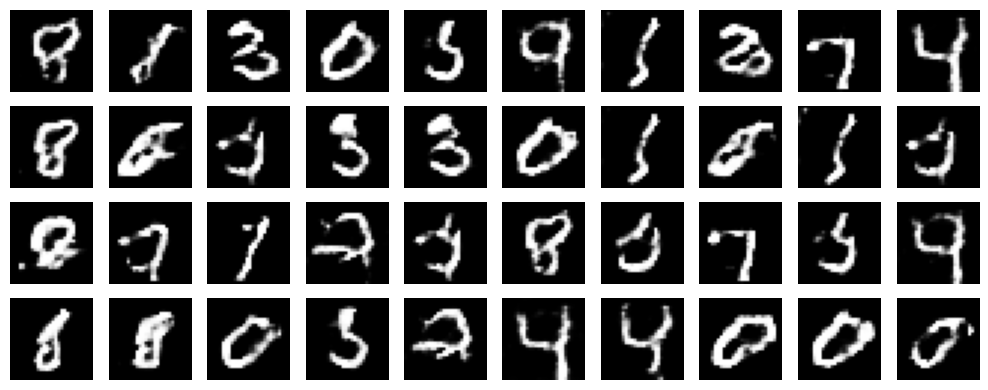

Époque 12 D / G [1.1983626624371142, 0.9067559980331583]


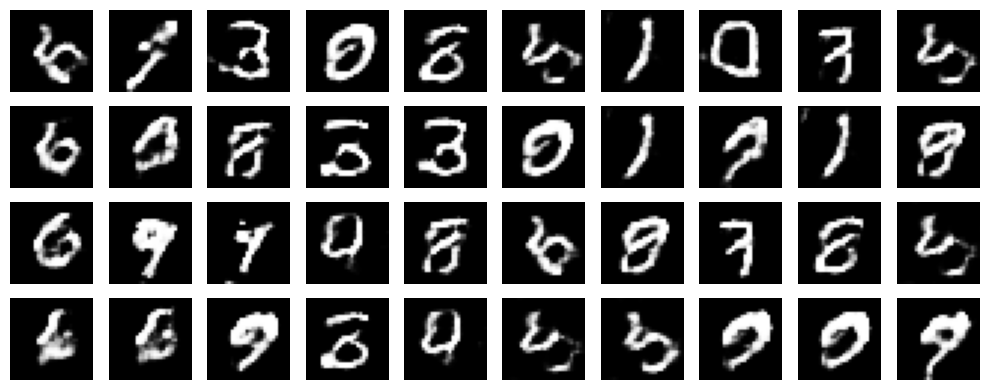

Époque 13 D / G [1.189702512355561, 0.9201209579376464]


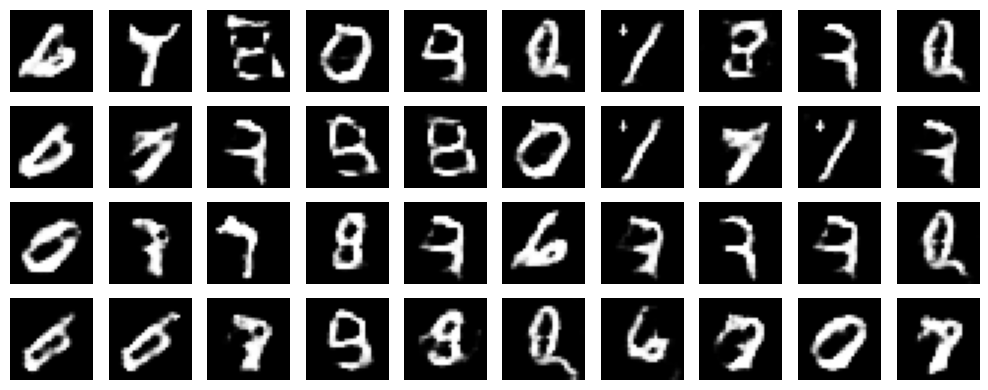

Époque 14 D / G [1.1593620127819955, 0.959703373401723]


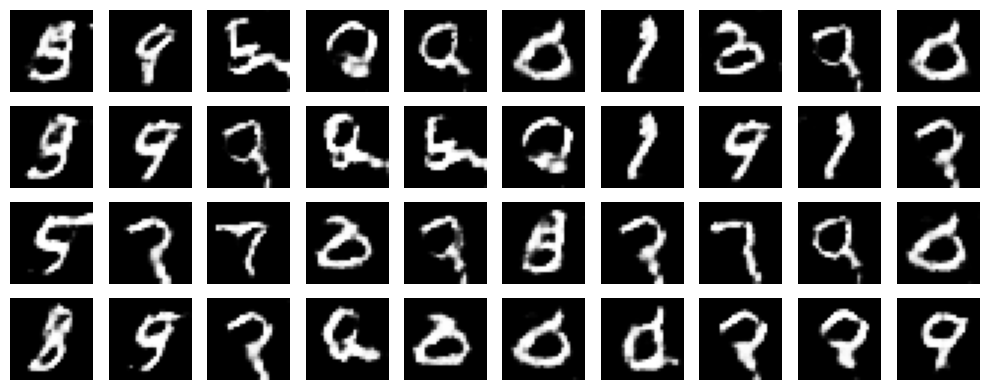

Époque 15 D / G [1.1301779396990512, 1.0138678368101728]


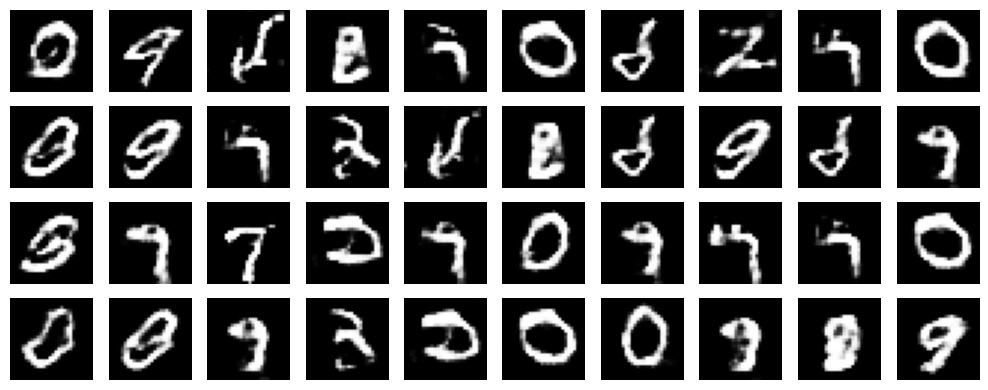

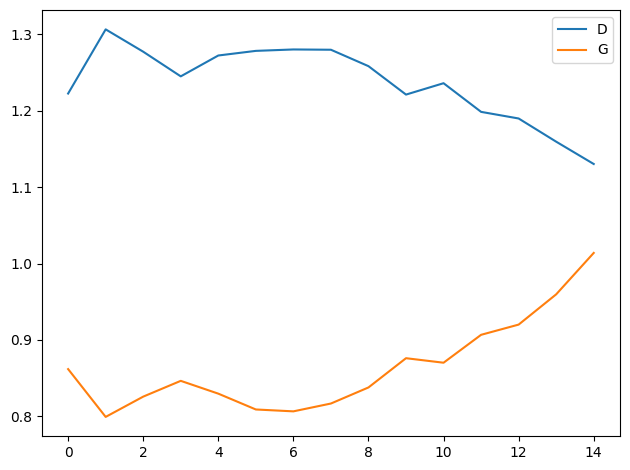

In [4]:
# Entraîner le Mini-StyleGAN sur MNIST complet pendant 15 époques.
og=torch.optim.Adam(G.parameters(),lr=.0002,betas=(.5,.999));od=torch.optim.Adam(D.parameters(),lr=.0002,betas=(.5,.999));bce=nn.BCELoss()
fixed=torch.randn(40,64,device=device);fixednoise=[torch.randn(40,1,s,s,device=device) for s in [7,14,28]];history=[]
for epoch in range(15):
    ld_sum=lg_sum=0
    for x,_ in loader:
        x=x.to(device);z=torch.randn(len(x),64,device=device);fake=G(z)
        od.zero_grad();ld=bce(D(x),torch.ones(len(x),1,device=device))+bce(D(fake.detach()),torch.zeros(len(x),1,device=device));ld.backward();od.step()
        og.zero_grad();lg=bce(D(G(z)),torch.ones(len(x),1,device=device));lg.backward();og.step();ld_sum+=ld.item();lg_sum+=lg.item()
    history.append([ld_sum/len(loader),lg_sum/len(loader)]);print('Époque',epoch+1,'D / G',history[-1])
    with torch.no_grad():grille(G(fixed,noises=fixednoise),'epoque_'+str(epoch+1))
plt.plot(np.array(history)[:,0],label='D');plt.plot(np.array(history)[:,1],label='G');plt.legend();figure('pertes_stylegan')
G.eval();torch.save(G.state_dict(),'models/mini_stylegan.pt')


## Q13–Q16 : troncature, interpolation, style mixing et bruit
Les mêmes bruits sont utilisés pour comparer les styles. Seule l’expérience bruit fait varier le bruit à style fixe. Les effets sont pédagogiques : ils ne reproduisent pas le contrôle sémantique d’un StyleGAN haute résolution.

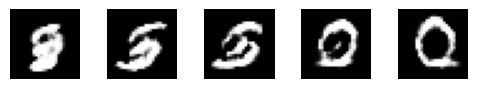

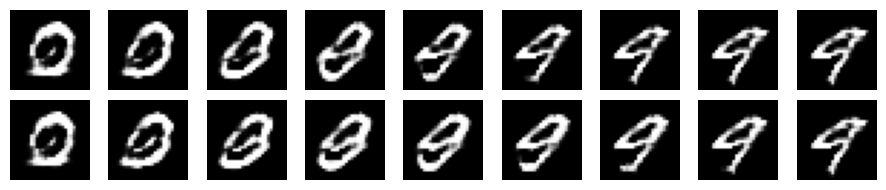

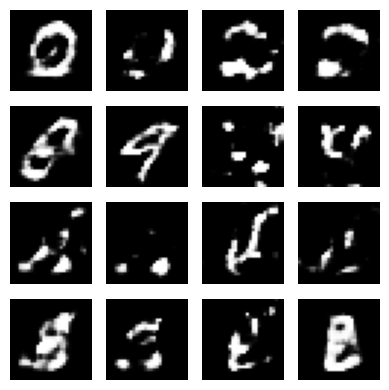

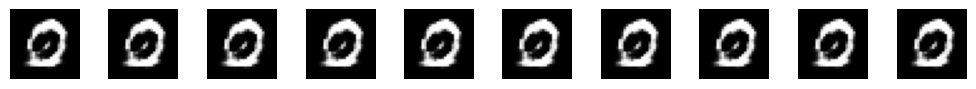

Variation moyenne absolue à style fixe : 0.0033420827239751816


In [5]:
# Calculer la moyenne empirique de W et faire varier psi.
with torch.no_grad():
    wmean=G.mapper(torch.randn(2000,64,device=device)).mean(0,keepdim=True);wa=G.mapper(fixed[:1]);wb=G.mapper(fixed[1:2])
    zeros=[torch.zeros(1,1,s,s,device=device) for s in [7,14,28]]
    trunc=torch.cat([G.synthese(wmean+psi*(wa-wmean),noises=zeros) for psi in [0,.3,.7,1,1.5]])
    grille(trunc,'troncature',5)
    steps=torch.linspace(0,1,9,device=device)
    in_z=torch.cat([G((1-t)*fixed[:1]+t*fixed[1:2],noises=zeros) for t in steps])
    in_w=torch.cat([G.synthese((1-t)*wa+t*wb,noises=zeros) for t in steps]);grille(torch.cat([in_z,in_w]),'interpolation_z_w',9)
    codes=fixed[:4];styles=G.mapper(codes)
    mixed=torch.cat([G.synthese(styles[i:i+1],styles[j:j+1],cut=1,noises=zeros) for i in range(4) for j in range(4)])
    grille(mixed,'style_mixing',4)
    noiseimgs=G(fixed[:1].repeat(10,1));grille(noiseimgs,'bruit_seul',10)
    print('Variation moyenne absolue à style fixe :',float((noiseimgs-noiseimgs[:1]).abs().mean()))


## Q17 : projection t-SNE limitée
La projection montre le voisinage dans W ; elle ne démontre pas à elle seule une séparation sémantique.

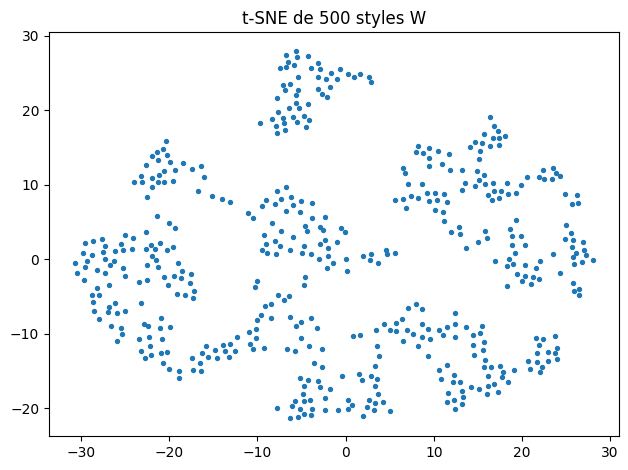

174

In [6]:
# Limiter les points et les threads pour éviter les blocages.
with torch.no_grad():w=G.mapper(torch.randn(500,64,device=device)).cpu().numpy()
with threadpool_limits(limits=4):embedding=TSNE(n_components=2,perplexity=25,random_state=42,n_jobs=1,init='pca',learning_rate='auto').fit_transform(w)
plt.scatter(embedding[:,0],embedding[:,1],s=8);plt.title('t-SNE de 500 styles W');figure('tsne_w')
Path('resultats.json').write_text(json.dumps({'epochs':15,'train_size':len(train),'device':str(device),'loss_last':history[-1],'noise_variation':float((noiseimgs-noiseimgs[:1]).abs().mean())},indent=2))


## Q18–Q20 : StyleGAN2, limites et conclusion
StyleGAN2 module les poids de convolution avec le style et les démodule pour contrôler leur amplitude. Sa régularisation de longueur de chemin encourage une variation plus régulière de l’image quand le latent varie. Notre modèle utilise AdaIN, pas ces mécanismes.

Limites : MNIST est petit et monochrome ; résolution 28×28 ; réseau peu profond ; entraînement court ; absence des régularisations avancées et des moyens de calcul des grands modèles FFHQ/LSUN. Les résultats doivent être jugés à partir des grilles réellement produites ; les pertes seules ne prouvent ni qualité ni diversité. Améliorations possibles : entraînement plus long, étude de stabilité et évaluation quantitative indépendante.

In [7]:
# Vérifier les dimensions et la finitude des sorties du modèle sauvegardé.
assert G(torch.randn(2,64,device=device)).shape==(2,1,28,28)
assert torch.isfinite(G(torch.randn(2,64,device=device))).all()
print('Vérifications : dimensions et valeurs finies OK')


Vérifications : dimensions et valeurs finies OK


## Analyse des résultats observés

L'entraînement a utilisé 15 époques et 60000 images MNIST sur cuda. Les pertes moyennes de la dernière époque sont D=1.1302 et G=1.0139. Ces deux fonctions ont des échelles et des objectifs différents : leur comparaison directe ne mesure pas une exactitude de classification.

La variation absolue moyenne des pixels à style fixe et bruit variable est 0.003342 sur l'échelle [-1,1]. Cette mesure confirme un effet numérique du bruit ; sa portée perceptuelle dépend des grilles. La matrice de mélange utilise le style de ligne au premier bloc 7×7 et le style de colonne aux blocs 14×14 et 28×28.

La troncature ramène W vers sa moyenne et réduit la variation des styles. L'interpolation en Z traverse le mapping non linéaire, tandis que celle en W relie directement les styles. La projection t-SNE de 500 points n'est pas étiquetée par classe : elle ne démontre aucune séparation sémantique des chiffres.

La dernière grille du second essai contient plusieurs formes différentes, dont des 0 et des 9 reconnaissables, ainsi que des formes ambiguës. Pour la paire illustrée, le passage en W semble plus progressif que celui en Z ; cette observation qualitative ne vaut que pour cet exemple. Dans la matrice de mélange, plusieurs cases hors diagonale sont fragmentées : le modèle n'a donc pas appris une séparation fiable entre styles grossiers et fins. La troncature vers la moyenne change même la catégorie apparente du chiffre ; elle ne garantit pas une meilleure qualité pour chaque valeur de psi. À code fixé, le bruit laisse globalement la forme stable et produit ici de petites variations de contour/intensité.

Le premier essai de 15 époques s'est effondré vers une forme presque unique ; ses sorties sont conservées dans `premier_essai_effondrement/`. Une seconde exécution de 15 époques ajoute une statistique d'écart-type du batch au discriminateur, suivie d'une convolution. Les figures principales correspondent à cette seconde exécution. Cette comparaison de deux entraînements ne permet pas d'attribuer quantitativement tout écart à cette seule modification.

Les grilles successives permettent d'inspecter l'apparition de structures et les défauts conservés. Le modèle pédagogique possède seulement trois blocs de synthèse et n'utilise ni convolutions modulées/démodulées ni régularisation de longueur de chemin de StyleGAN2. Un entraînement de 15 époques ne suffit pas à revendiquer la qualité d'un modèle haute résolution.
